# 05 · Peaked circuits at laptop scale: build them, then measure what a small-MPS attack needs

**Why this notebook.** Track 2 of the call asks for adversarial classical simulation of published quantum-advantage
claims. Peaked circuits are the sponsor's own advantage genre: a circuit whose output distribution puts a large
weight on one hidden bitstring, so a quantum run can be verified by reading off the peak (Aaronson & Zhang
[AZ]; BlueQubit's peaked-circuit work [BQ], references at the end). The prototype campaign did not attack peaked
circuits. This notebook is a self-contained, laptop-scale rehearsal of that attack: it builds peaked circuits
honestly, runs a cheap tensor-network attack on them, and measures what the attack actually needs.

**What it does — locally, no API key:**
1. Builds peaked circuits: a random 1D brickwork R of Haar two-qubit gates followed by a "peaking" brickwork P,
   whose gates are optimised by exact environment sweeps (`peaked_lite.py`, numpy only) so that P·R sends |0…0⟩ to a
   hidden random bitstring s. The circuits of §1 are cross-checked against qiskit's statevector; the attack
   instances use the same code.
2. Attacks them with a bond-limited MPS (`mps_lite.py`, the simulator validated in notebook 03). The attacker samples
   the truncated state and keeps the sample with the largest MPS amplitude. It never uses a dense vector and never
   sees s. Dense vectors are used only to score the attack.
3. Finds that, on 1D circuits, the attack needs far less than faithful simulation, and that truncation keeps more
   peak weight than noise of the same fidelity would, sometimes more than the exact state. A final-state experiment
   isolates why.
4. Hides the wire order behind a secret static relabeling (a deliberately weak toy version of the permutation hiding
   in [BQ]) and recovers it from the gate list.
5. Replaces the chain by all-to-all gates, as in BlueQubit's circuits, and measures where the cheap attack stops.

Scope (kept small so it runs in minutes on a laptop CPU, 2 BLAS threads): ≤ 16 qubits, 1D nearest-neighbour
brickwork, all-to-all in §2c.
These are **our own** constructed circuits, not BlueQubit's challenge circuits; the notebook makes no claim about
those. The point is the measurement protocol the scale-up would run on them.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "2")
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from qiskit.quantum_info import Statevector
import nbcommon as C
import peaked_lite as PK
from mps_lite import MPS

C.style()
T0 = time.time()
RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]       # ordinal blue ramp: deeper = darker
N_COLOR = {12: C.AQUA, 16: C.BLUE}

def bits_index(s):
    return sum(int(c) << k for k, c in enumerate(s))

def make_instance(n, d_rand, d_peak, seed, sweeps=60):
    """Random brickwork R (depth d_rand) + optimised peaking brickwork P (depth d_peak), hidden string s."""
    rng = np.random.default_rng(seed)
    R = PK.brickwork(n, d_rand, rng)
    P0 = PK.brickwork(n, d_peak, rng, first_layer=d_rand)      # continues the brick pattern: C looks uniform
    s = "".join(map(str, rng.integers(0, 2, n)))
    t = time.time()
    P, hist = PK.optimise_peak(n, R, P0, s, sweeps=sweeps)
    gates = R + P
    psi = PK.run(PK.zero_state(n), n, gates)
    p = np.abs(psi) ** 2
    return dict(n=n, d_rand=d_rand, d_peak=d_peak, seed=seed, s=s, gates=gates, psi=psi, hist=hist,
                peak=float(p[bits_index(s)]), argmax_ok=bool(np.argmax(p) == bits_index(s)),
                second=float(np.sort(p)[-2]), opt_s=time.time() - t)

## 1 · Building peaked circuits

For a fixed random part R, the amplitude ⟨s|P·R|0…0⟩ is linear in each gate G of P: it equals Tr(G·E), where the
4×4 environment E is obtained by contracting everything else. The unitary that maximises |Tr(G·E)| is G = Y·X† for
E = X·S·Y† (SVD), and the new amplitude is the sum of singular values (the standard environment update of
tensor-network optimisation, e.g. Evenbly & Vidal, Phys. Rev. B 79, 144108 (2009)). Sweeping it over all gates of P
cannot decrease the peak weight |⟨s|P·R|0…0⟩|²; it converges to a local optimum (no restarts are used here).

First run: 12 qubits, R of depth 8, peaking depth 2 to 8, three seeds each.

In [2]:
N1, DR1, SEEDS = 12, 8, (0, 1, 2)
build = [make_instance(N1, DR1, dp, 100 * dp + sd) for dp in (2, 4, 6, 8) for sd in SEEDS]
qk_err = max(float(np.max(np.abs(np.asarray(Statevector.from_instruction(PK.to_qiskit(N1, b["gates"])).data) - b["psi"])))
             for b in build)
monotone = all(np.all(np.diff(b["hist"]) > -1e-12) for b in build)
rows = []
for dp in (2, 4, 6, 8):
    bs = [b for b in build if b["d_peak"] == dp]
    pk = [b["peak"] for b in bs]
    rows.append(f"| {dp} | {np.median(pk):.3f} ({min(pk):.3f}–{max(pk):.3f}) | "
                f"{np.median([b['hist'][0] for b in bs]):.1e} | {max(len(b['hist']) - 1 for b in bs)} | "
                f"{sum(b['argmax_ok'] for b in bs)}/{len(bs)} | {max(b['second'] for b in bs):.1e} | "
                f"{np.median(pk) * 2 ** N1:,.0f}× |")
display(Markdown(
    f"**{N1} qubits, random depth {DR1}, three seeds per row.** Uniform background 2⁻ⁿ = {2.0 ** -N1:.1e}.\n\n"
    "| peaking depth | peak weight, median (range) | before optimising (median) | sweeps used (max) | "
    "argmax = s | largest non-peak probability | peak / 2⁻ⁿ (median) |\n|---|---|---|---|---|---|---|\n" + "\n".join(rows) +
    "\n\nSweeps stop when the gain falls below 1e-10 or at the cap of 60; rows at the cap had not fully converged, so "
    "their peaks are the values reached at the cap."))
print(f"peaked_lite vs qiskit Statevector, {len(build)} circuits: max |amplitude difference| = {qk_err:.1e}")
print(f"peak weight non-decreasing in every sweep of every run: {monotone}")
assert qk_err < 1e-10 and monotone and all(b["argmax_ok"] for b in build)

**12 qubits, random depth 8, three seeds per row.** Uniform background 2⁻ⁿ = 2.4e-04.

| peaking depth | peak weight, median (range) | before optimising (median) | sweeps used (max) | argmax = s | largest non-peak probability | peak / 2⁻ⁿ (median) |
|---|---|---|---|---|---|---|
| 2 | 0.120 (0.100–0.204) | 1.3e-04 | 60 | 3/3 | 1.1e-02 | 490× |
| 4 | 0.417 (0.409–0.450) | 6.3e-05 | 60 | 3/3 | 6.1e-03 | 1,706× |
| 6 | 0.545 (0.452–0.577) | 2.1e-04 | 60 | 3/3 | 3.7e-03 | 2,232× |
| 8 | 0.561 (0.550–0.604) | 4.4e-04 | 60 | 3/3 | 3.0e-03 | 2,299× |

Sweeps stop when the gain falls below 1e-10 or at the cap of 60; rows at the cap had not fully converged, so their peaks are the values reached at the cap.

peaked_lite vs qiskit Statevector, 12 circuits: max |amplitude difference| = 0.0e+00
peak weight non-decreasing in every sweep of every run: True


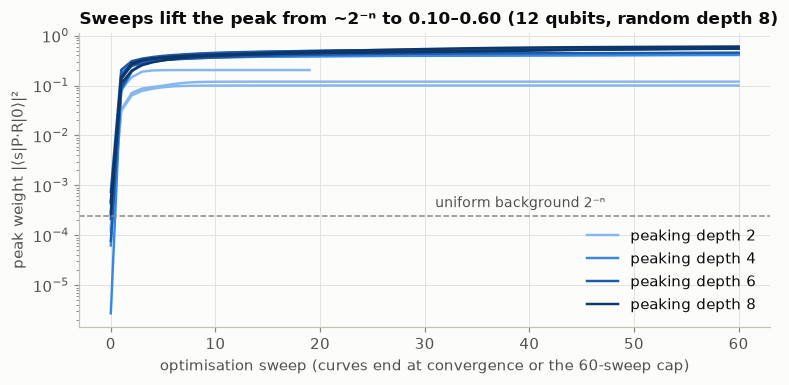

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
for i, dp in enumerate((2, 4, 6, 8)):
    for b in [b for b in build if b["d_peak"] == dp]:
        ax.plot(np.arange(len(b["hist"])), b["hist"], color=RAMP[i], lw=1.6,
                label=f"peaking depth {dp}" if b["seed"] % 100 == 0 else None)
ax.axhline(2.0 ** -N1, color=C.MUTED, ls="--", lw=1)
ax.text(31, 2.0 ** -N1 * 1.5, "uniform background 2⁻ⁿ", color=C.INK_2, fontsize=9)
ax.set(yscale="log", xlabel="optimisation sweep (curves end at convergence or the 60-sweep cap)",
       ylabel="peak weight |⟨s|P·R|0⟩|²",
       title=f"Sweeps lift the peak from ~2⁻ⁿ to {min(b['peak'] for b in build):.2f}–{max(b['peak'] for b in build):.2f} "
             f"({N1} qubits, random depth {DR1})")
ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

**Cross-check against the literature.** Aaronson & Zhang report an average peak weight of about 0.2 for 12 qubits
with 40 random layers and 10 peaking layers, using gradient training (Adam) with random restarts (arXiv:2404.14493).
Their layer and gate parametrisation may differ in detail from ours, so this is an order-of-magnitude check of the
optimiser, not a replication.

In [4]:
az = [make_instance(12, 40, 10, 500 + sd, sweeps=100) for sd in range(5)]
az_peaks = [b["peak"] for b in az]
display(Markdown(f"Environment sweeps, 12 qubits, random depth 40, peaking depth 10, 5 seeds: peak weight "
                 f"**{np.mean(az_peaks):.3f}** on average (range {min(az_peaks):.3f}–{max(az_peaks):.3f}); "
                 f"argmax = s in {sum(b['argmax_ok'] for b in az)}/5."))

Environment sweeps, 12 qubits, random depth 40, peaking depth 10, 5 seeds: peak weight **0.186** on average (range 0.184–0.187); argmax = s in 5/5.

## 2 · The attack: sample a bond-limited MPS, keep the best-scoring sample

Attack instances: 12 and 16 qubits, peaking depth 8, random depth 4 to 24, three seeds each. The attacker gets the
gate list only. For each bond dimension χ it simulates the whole circuit with `mps_lite` (SVD truncation to χ after
every gate), draws 2,000 samples from the truncated MPS, scores each distinct sample by its MPS amplitude (an
O(nχ²) contraction), and reports the top-scoring one. Cost is polynomial in n and χ throughout.

Scoring uses the dense exact state, which an attacker would not have: **F** = |⟨ψ_exact|ψ_χ⟩|² (fidelity of the
truncated simulation), **p_χ** = |⟨s|ψ_χ⟩|² (peak weight in the truncated state), and whether the reported string
equals s. At χ = 2^(n/2) the MPS is exact.

Random depths 4 and 8 are at or below the peaking depth. Aaronson & Zhang call that regime trivial, because P can
simply undo R. They are included as the easy end of the scale; depths 16 and 24 are the non-trivial regime.

In [5]:
SHOTS = 2000
DEPTHS = (4, 8, 16, 24)
attack, insts = [], {}
for n in (12, 16):
    chis = [c for c in (1, 2, 4, 8, 16, 32, 64, 128, 256) if c <= 2 ** (n // 2)]
    for dr in DEPTHS:
        for sd in SEEDS:
            inst = make_instance(n, dr, 8, 10_000 * n + 100 * dr + sd)
            insts[(n, dr, sd)] = inst
            for chi in chis:
                t = time.time()
                m = MPS(n, chi).run(inst["gates"])
                t_sim = time.time() - t
                F = float(abs(np.vdot(inst["psi"], m.to_statevector())) ** 2)
                p_chi = float(abs(PK.mps_amplitude(m, inst["s"])) ** 2)
                guess, w, ncand = PK.mps_attack(m, SHOTS, np.random.default_rng(sd))
                attack.append(dict(n=n, d_rand=dr, seed=sd, chi=chi, F=F, peak=inst["peak"], p_chi=p_chi,
                                   ok=guess == inst["s"], guess=guess, ncand=ncand, t_sim=t_sim, argmax_ok=inst["argmax_ok"],
                                   max_bond=m.max_bond))
print(f"{len(attack)} attack runs (instance × χ) on {len({(r['n'], r['d_rand'], r['seed']) for r in attack})} instances")

def per_instance(rows):
    out = {}
    for r in rows:
        out.setdefault((r["n"], r["d_rand"], r["seed"]), []).append(r)
    return out

def chi_threshold(rs, pred):
    """Smallest χ from which pred holds at every larger χ (None if never)."""
    rs = sorted(rs, key=lambda r: r["chi"])
    for i, r in enumerate(rs):
        if all(pred(x) for x in rs[i:]):
            return r["chi"]
    return None

def stop_rule(rs):
    """Attacker-side stopping rule (no knowledge of s): double χ until the top candidate stops changing.
    Returns (largest χ simulated, reported string == s)."""
    rs = sorted(rs, key=lambda r: r["chi"])
    for x, y in zip(rs, rs[1:]):
        if x["guess"] == y["guess"]:
            return y["chi"], x["ok"]
    return rs[-1]["chi"], rs[-1]["ok"]

inst_rows = []
for (n, dr, sd), rs in sorted(per_instance(attack).items()):
    c_ok = chi_threshold(rs, lambda r: r["ok"])
    st_chi, st_ok = stop_rule(rs)
    inst_rows.append(dict(n=n, d_rand=dr, seed=sd, peak=rs[0]["peak"], chi_ok=c_ok,
                          chi_99=chi_threshold(rs, lambda r: r["F"] >= 0.99),
                          F_at_ok=next(r["F"] for r in rs if r["chi"] == c_ok), stop_chi=st_chi, stop_ok=st_ok))
tab = ["| n | random depth | exact peak p (median) | χ to recover s (median, range) | χ for F ≥ 0.99 (median, range) | "
       "F at the recovering χ (median) | stopping rule: correct, χ simulated (median) |", "|---|---|---|---|---|---|---|"]
for n in (12, 16):
    for dr in DEPTHS:
        g = [r for r in inst_rows if r["n"] == n and r["d_rand"] == dr]
        ok, f99 = [r["chi_ok"] for r in g], [r["chi_99"] for r in g]
        tab.append(f"| {n} | {dr}{' (trivial)' if dr <= 8 else ''} | {np.median([r['peak'] for r in g]):.3f} | "
                   f"{int(np.median(ok))} ({min(ok)}–{max(ok)}) | {int(np.median(f99))} ({min(f99)}–{max(f99)}) | "
                   f"{np.median([r['F_at_ok'] for r in g]):.3f} | {sum(r['stop_ok'] for r in g)}/{len(g)}, "
                   f"{int(np.median([r['stop_chi'] for r in g]))} |")
display(Markdown("\n".join(tab) + "\n\n*Stopping rule*: the attacker cannot check its answer against s, so it doubles χ "
                 "until the top-scoring candidate is the same at χ and 2χ, and reports that candidate."))

192 attack runs (instance × χ) on 24 instances


| n | random depth | exact peak p (median) | χ to recover s (median, range) | χ for F ≥ 0.99 (median, range) | F at the recovering χ (median) | stopping rule: correct, χ simulated (median) |
|---|---|---|---|---|---|---|
| 12 | 4 (trivial) | 0.925 | 2 (2–2) | 16 (16–16) | 0.450 | 3/3, 4 |
| 12 | 8 (trivial) | 0.602 | 2 (2–4) | 32 (32–64) | 0.061 | 3/3, 4 |
| 12 | 16 | 0.196 | 4 (4–4) | 64 (64–64) | 0.020 | 3/3, 8 |
| 12 | 24 | 0.148 | 8 (8–8) | 64 (64–64) | 0.014 | 3/3, 16 |
| 16 | 4 (trivial) | 0.917 | 2 (1–2) | 16 (16–16) | 0.311 | 3/3, 4 |
| 16 | 8 (trivial) | 0.453 | 2 (2–2) | 64 (64–64) | 0.048 | 3/3, 4 |
| 16 | 16 | 0.077 | 4 (4–4) | 256 (256–256) | 0.002 | 3/3, 8 |
| 16 | 24 | 0.019 | 8 (8–16) | 256 (256–256) | 0.002 | 3/3, 16 |

*Stopping rule*: the attacker cannot check its answer against s, so it doubles χ until the top-scoring candidate is the same at χ and 2χ, and reports that candidate.

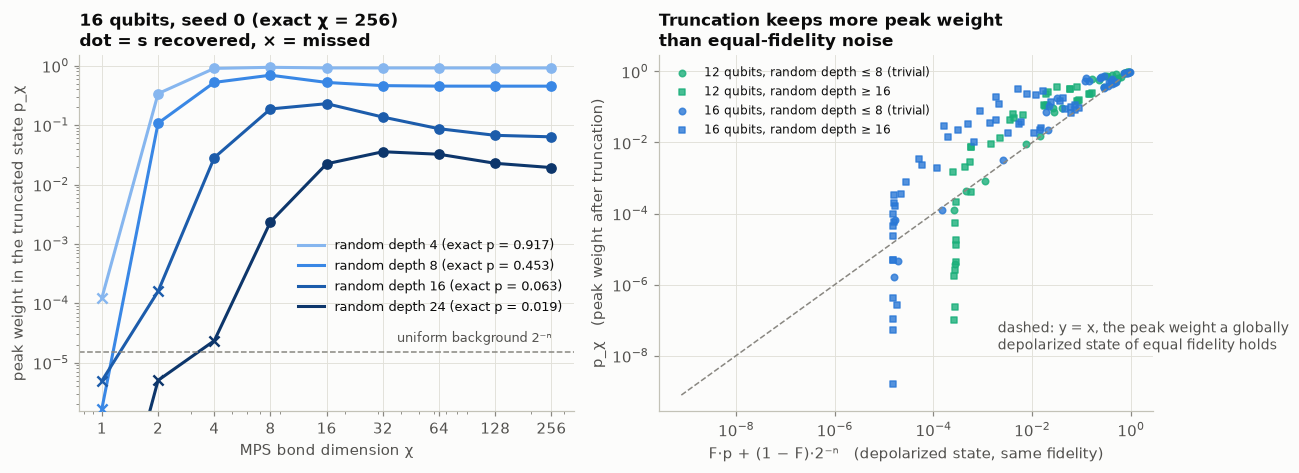

**Reading.** In the non-trivial regime (random depth 16 and 24, deeper than the peaking part; 12 instances) the attack recovered the hidden string at χ = 4–16 (median 6), while a faithful simulation (F ≥ 0.99) needed the full exact bond dimension in 12 of 12 instances (64 at 12 qubits, 256 at 16). Lossy runs (F < 0.99) recovered s down to F = 1.7e-03. The attacker-side stopping rule reported the right string in 12 of 12 non-trivial instances (24 of 24 overall). In 83% of the 142 lossy runs the truncated state held more peak weight than a globally depolarized state of the same fidelity, F·p + (1 − F)·2⁻ⁿ (the noise model of Zhang, arXiv:2510.00132, §4.5; median ratio 1.8); in 67 of them it exceeded the exact peak p itself, which depolarizing noise never does.

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12.0, 4.4))
n_show, sd_show = 16, 0
for i, dr in enumerate(DEPTHS):
    rs = sorted([r for r in attack if r["n"] == n_show and r["d_rand"] == dr and r["seed"] == sd_show],
                key=lambda r: r["chi"])
    x, y = [r["chi"] for r in rs], [r["p_chi"] for r in rs]
    ax[0].plot(x, y, color=RAMP[i], label=f"random depth {dr} (exact p = {rs[-1]['peak']:.3f})")
    ax[0].scatter([r["chi"] for r in rs if r["ok"]], [r["p_chi"] for r in rs if r["ok"]], color=RAMP[i], s=36, zorder=3)
    ax[0].scatter([r["chi"] for r in rs if not r["ok"]], [r["p_chi"] for r in rs if not r["ok"]],
                  color=RAMP[i], marker="x", s=44, lw=1.6, zorder=3)
ax[0].axhline(2.0 ** -n_show, color=C.MUTED, ls="--", lw=1)
ax[0].text(256, 2.0 ** -n_show * 1.3, "uniform background 2⁻ⁿ", color=C.INK_2, fontsize=8.5, ha="right", va="bottom")
ax[0].set(xscale="log", yscale="log", xlabel="MPS bond dimension χ", ylabel="peak weight in the truncated state p_χ",
          title=f"{n_show} qubits, seed {sd_show} (exact χ = {2 ** (n_show // 2)})\ndot = s recovered, × = missed")
ax[0].title.set_fontsize(10.5)
ax[0].set_ylim(2.0 ** -n_show * 0.1, 1.5)
ax[0].set_xticks([1, 2, 4, 8, 16, 32, 64, 128, 256]); ax[0].set_xticklabels([1, 2, 4, 8, 16, 32, 64, 128, 256])
ax[0].legend(loc="lower right", fontsize=8.5, bbox_to_anchor=(1.0, 0.24))   # sits between the background line and the curves

def depol(r):
    """Peak weight of a globally depolarized state with the same fidelity: F·p + (1 − F)·2⁻ⁿ."""
    return r["F"] * r["peak"] + (1 - r["F"]) * 2.0 ** -r["n"]

lossy = [r for r in attack if r["F"] < 0.99]
for n in (12, 16):
    for triv, mk in ((True, "o"), (False, "s")):
        rs = [r for r in lossy if r["n"] == n and (r["d_rand"] <= 8) == triv]
        ax[1].scatter([depol(r) for r in rs], [r["p_chi"] for r in rs], s=18, marker=mk, color=N_COLOR[n], alpha=0.8,
                      label=f"{n} qubits, random depth {'≤ 8 (trivial)' if triv else '≥ 16'}")
lo = min(min(depol(r) for r in lossy), min(r["p_chi"] for r in lossy)) / 2
ax[1].plot([lo, 1], [lo, 1], color=C.MUTED, ls="--", lw=1)
ax[1].text(2e-3, 1.5e-8, "dashed: y = x, the peak weight a globally\ndepolarized state of equal fidelity holds",
           color=C.INK_2, fontsize=9)
ax[1].set(xscale="log", yscale="log", xlabel="F·p + (1 − F)·2⁻ⁿ   (depolarized state, same fidelity)",
          ylabel="p_χ   (peak weight after truncation)",
          title="Truncation keeps more peak weight\nthan equal-fidelity noise")
ax[1].title.set_fontsize(10.5)
ax[1].legend(loc="upper left", fontsize=8)
fig.tight_layout(); plt.show()

amp = np.array([r["p_chi"] / depol(r) for r in lossy])
NT = [r for r in inst_rows if r["d_rand"] > 8]                    # random depth > peaking depth: non-trivial regime
ok_nt = [r for r in attack if r["ok"] and r["d_rand"] > 8 and r["F"] < 0.99]
ex_nt = {n: 2 ** (n // 2) for n in (12, 16)}
display(Markdown(
    f"**Reading.** In the non-trivial regime (random depth 16 and 24, deeper than the peaking part; "
    f"{len(NT)} instances) the attack recovered the hidden string at χ = {min(r['chi_ok'] for r in NT)}–"
    f"{max(r['chi_ok'] for r in NT)} (median {np.median([r['chi_ok'] for r in NT]):.0f}), while a faithful simulation "
    f"(F ≥ 0.99) needed the full exact bond dimension in "
    f"{sum(r['chi_99'] == ex_nt[r['n']] for r in NT)} of {len(NT)} instances (64 at 12 qubits, 256 at 16). Lossy runs "
    f"(F < 0.99) recovered s down to F = {min(r['F'] for r in ok_nt):.1e}. The attacker-side stopping rule reported the "
    f"right string in {sum(r['stop_ok'] for r in NT)} of {len(NT)} non-trivial instances "
    f"({sum(r['stop_ok'] for r in inst_rows)} of {len(inst_rows)} overall). "
    f"In {np.mean(amp > 1) * 100:.0f}% of the {len(lossy)} lossy runs the truncated state held more peak weight than "
    f"a globally depolarized state of the same fidelity, F·p + (1 − F)·2⁻ⁿ (the noise model of Zhang, arXiv:2510.00132, "
    f"§4.5; median ratio {np.median(amp):.1f}); in {sum(r['p_chi'] > r['peak'] for r in lossy)} of them it exceeded "
    f"the exact peak p itself, which depolarizing noise never does."))

### 2b · A hidden wire order

BlueQubit's construction hides a wire permutation [BQ], and the attack in [KD] has to get around it. A deliberately
weak toy version: publish each 16-qubit, random-depth-16 and -24 circuit with its wires relabeled by a secret random
permutation. The gates are unchanged, but nearest neighbours on the chain are no longer adjacent labels. Attacker A
simulates in the published label order (`mps_lite` routes distant gates with SWAPs, each truncated to χ, the layout
damage of notebook 03). Attacker B first recovers an order from the published gate list alone: reverse Cuthill–McKee
(scipy) on the graph of qubit pairs that share a gate: a standard bandwidth-reduction heuristic (no optimality
guarantee; on a path graph it returns the path or its mirror). Attacker A, which ignores the gate list, is a strawman
kept only to price the hiding.

In [7]:
import scipy.sparse as sp
from scipy.sparse.csgraph import reverse_cuthill_mckee

def relabel(gates, pos):
    return [(g, (int(pos[a]), int(pos[b]))) for g, (a, b) in gates]

def chi_to_recover(gates, s, chis, seed):
    psi = PK.run(PK.zero_state(len(s)), len(s), gates)
    rs = []
    for chi in chis:
        m = MPS(len(s), chi).run(gates)
        guess, _, _ = PK.mps_attack(m, SHOTS, np.random.default_rng(seed))
        rs.append(dict(chi=chi, ok=guess == s, F=float(abs(np.vdot(psi, m.to_statevector())) ** 2), n_svd=m.n_svd))
    c = chi_threshold(rs, lambda r: r["ok"])
    return c, next(r for r in rs if r["chi"] == c), rs

hid = []
for dr in (16, 24):
    for sd in SEEDS:
        inst = insts[(16, dr, sd)]
        perm = np.random.default_rng(77 + 100 * dr + sd).permutation(16)       # secret: wire q -> label perm[q]
        pub = relabel(inst["gates"], perm)
        s_pub = "".join(inst["s"][int(np.where(perm == k)[0][0])] for k in range(16))
        adj = sp.lil_matrix((16, 16))
        for _, (a, b) in pub:
            adj[a, b] = adj[b, a] = 1
        order = reverse_cuthill_mckee(adj.tocsr(), symmetric_mode=True)          # order[site] = label
        pos = np.empty(16, int); pos[order] = np.arange(16)
        reo, s_reo = relabel(pub, pos), "".join(s_pub[order[k]] for k in range(16))
        chis = [1, 2, 4, 8, 16, 32, 64, 128, 256]
        ca, ra, _ = chi_to_recover(pub, s_pub, chis, sd)
        cb, rb, _ = chi_to_recover(reo, s_reo, chis, sd)
        chi_orig = next(r["chi_ok"] for r in inst_rows if (r["n"], r["d_rand"], r["seed"]) == (16, dr, sd))
        hid.append(dict(d_rand=dr, seed=sd, chi_orig=chi_orig, bw_pub=max(abs(a - b) for _, (a, b) in pub),
                        bw_rcm=max(abs(a - b) for _, (a, b) in reo), chi_a=ca, F_a=ra["F"], svd_a=ra["n_svd"],
                        chi_b=cb, F_b=rb["F"], svd_b=rb["n_svd"]))
display(Markdown(
    "| random depth · seed | largest gate distance, published → after RCM | A: χ to recover (label order) | "
    "B: χ to recover (RCM order) | χ to recover, unhidden (§2) | SVDs per simulation, A vs B |\n"
    "|---|---|---|---|---|---|\n" +
    "\n".join(f"| {h['d_rand']} · {h['seed']} | {h['bw_pub']} → {h['bw_rcm']} | {h['chi_a']} (F = {h['F_a']:.1e}) | "
              f"{h['chi_b']} (F = {h['F_b']:.1e}) | {h['chi_orig']} | {h['svd_a']:,} vs {h['svd_b']:,} |" for h in hid)))
ratio_hid = [h["chi_a"] / h["chi_b"] for h in hid]
display(Markdown(
    f"**Reading.** The secret relabeling raised the χ the attack needs by a factor of {min(ratio_hid):.0f}–"
    f"{max(ratio_hid):.0f} (median {np.median(ratio_hid):.0f}) in the published order. Recovering the order from the gate "
    f"list gave back a chain (largest gate distance 1) in {sum(h['bw_rcm'] == 1 for h in hid)} of {len(hid)} "
    f"instances, and the attack then needed the same χ as on the unhidden circuit in "
    f"{sum(h['chi_b'] == h['chi_orig'] for h in hid)} of {len(hid)}"
    + ("" if all(h["chi_b"] == h["chi_orig"] for h in hid) else
       f" (largest ratio between the two: {max(max(h['chi_b'], h['chi_orig']) / min(h['chi_b'], h['chi_orig']) for h in hid):.0f})")
    + ". "
    f"That is easy here because a static relabeling leaves the gate graph a path, so this hiding costs an attacker "
    f"who reads the gate list nothing. §2c removes the path."))

| random depth · seed | largest gate distance, published → after RCM | A: χ to recover (label order) | B: χ to recover (RCM order) | χ to recover, unhidden (§2) | SVDs per simulation, A vs B |
|---|---|---|---|---|---|
| 16 · 0 | 15 → 1 | 64 (F = 1.3e-02) | 4 (F = 2.3e-03) | 4 | 1,764 vs 180 |
| 16 · 1 | 12 → 1 | 64 (F = 2.3e-02) | 4 (F = 9.7e-03) | 4 | 1,596 vs 180 |
| 16 · 2 | 13 → 1 | 64 (F = 2.8e-03) | 4 (F = 2.4e-03) | 4 | 2,004 vs 180 |
| 24 · 0 | 12 → 1 | 128 (F = 2.6e-02) | 8 (F = 2.3e-03) | 8 | 2,576 vs 240 |
| 24 · 1 | 11 → 1 | 128 (F = 2.4e-02) | 8 (F = 1.7e-03) | 8 | 2,544 vs 240 |
| 24 · 2 | 12 → 1 | 128 (F = 1.9e-02) | 16 (F = 6.5e-03) | 16 | 2,032 vs 240 |

**Reading.** The secret relabeling raised the χ the attack needs by a factor of 8–16 (median 16) in the published order. Recovering the order from the gate list gave back a chain (largest gate distance 1) in 6 of 6 instances, and the attack then needed the same χ as on the unhidden circuit in 6 of 6. That is easy here because a static relabeling leaves the gate graph a path, so this hiding costs an attacker who reads the gate list nothing. §2c removes the path.

### 2c · Where the cheap attack stops: all-to-all gates

The circuits so far are 1D chains, hidden or not. BlueQubit's circuits use all-to-all connectivity [BQ]. Here every
layer of R and of P acts on a uniformly random perfect matching of the qubits, so any pair can share a gate; P is
optimised exactly as in §1 (peaking depth 8, random depth 8 and 16, three seeds, 12 and 16 qubits). No wire order
makes these gates local, so the attacker can only pick the least-bad order. We compare the label order with the
better (by total gate distance) of two orders computed from the gate list alone: reverse Cuthill–McKee and a
simulated-annealing search over orders. Same attack and scoring as §2.

In [8]:
A2A_N = (12, 16)
def matching_layers(n, depth, rng):
    """`depth` layers of Haar gates, each layer on a uniformly random perfect matching of the n qubits."""
    gates = []
    for _ in range(depth):
        q = rng.permutation(n)
        gates += [(PK.haar_u4(rng), (int(q[2 * i]), int(q[2 * i + 1]))) for i in range(n // 2)]
    return gates

def gate_distance(gates, pos):
    return sum(abs(int(pos[a]) - int(pos[b])) for _, (a, b) in gates)

def rcm_pos(gates, n):
    adj = sp.lil_matrix((n, n))
    for _, (a, b) in gates:
        adj[a, b] = adj[b, a] = 1
    order = reverse_cuthill_mckee(adj.tocsr(), symmetric_mode=True)
    pos = np.empty(n, int); pos[order] = np.arange(n)
    return pos

def anneal_pos(gates, n, rng, steps=20_000):
    """Simulated annealing over wire orders, minimising total gate distance (gate list only)."""
    pos = np.arange(n); c = gate_distance(gates, pos); best = (c, pos.copy())
    for t in range(steps):
        temp = 2.0 * (1 - t / steps) + 1e-3
        i, j = rng.choice(n, 2, replace=False)
        pos[i], pos[j] = pos[j], pos[i]
        c2 = gate_distance(gates, pos)
        if c2 <= c or rng.random() < np.exp(-(c2 - c) / temp):
            c = c2
        else:
            pos[i], pos[j] = pos[j], pos[i]
        if c < best[0]:
            best = (c, pos.copy())
    return best[1]

def attack_rows(gates, s, chis, seed):
    psi = PK.run(PK.zero_state(len(s)), len(s), gates)
    rs = []
    for chi in chis:
        m = MPS(len(s), chi).run(gates)
        guess, _, _ = PK.mps_attack(m, SHOTS, np.random.default_rng(seed))
        rs.append(dict(chi=chi, ok=guess == s, F=float(abs(np.vdot(psi, m.to_statevector())) ** 2),
                       p_chi=float(abs(PK.mps_amplitude(m, s)) ** 2)))
    return rs

a2a = []
for n in A2A_N:
    chis = [c for c in (1, 2, 4, 8, 16, 32, 64, 128, 256) if c <= 2 ** (n // 2)]
    for dr in (8, 16):
        for sd in SEEDS:
            rng = np.random.default_rng(30_000_000 + 10_000 * n + 100 * dr + sd)
            R, P0 = matching_layers(n, dr, rng), matching_layers(n, 8, rng)
            s = "".join(map(str, rng.integers(0, 2, n)))
            P, _ = PK.optimise_peak(n, R, P0, s, sweeps=60)
            gates = R + P
            p = np.abs(PK.run(PK.zero_state(n), n, gates)) ** 2
            cand = {"RCM": rcm_pos(gates, n), "annealing": anneal_pos(gates, n, np.random.default_rng(sd))}
            best = min(cand, key=lambda k: gate_distance(gates, cand[k]))
            row = dict(n=n, d_rand=dr, seed=sd, peak=float(p[bits_index(s)]), argmax_ok=bool(np.argmax(p) == bits_index(s)),
                       proxy=best, chi_exact=2 ** (n // 2))
            for name, pos in (("label", np.arange(n)), ("proxy", cand[best])):
                g2 = relabel(gates, pos)
                s2 = "".join(s[int(np.where(pos == k)[0][0])] for k in range(n))
                rs = attack_rows(g2, s2, chis, sd)
                c = chi_threshold(rs, lambda r: r["ok"])
                row.update({f"dist_{name}": gate_distance(gates, pos), f"maxd_{name}": max(abs(int(pos[a]) - int(pos[b])) for _, (a, b) in gates),
                            f"chi_{name}": c, f"F_{name}": next(r["F"] for r in rs if r["chi"] == c), f"rs_{name}": rs})
            a2a.append(row)
print(f"all-to-all: {len(a2a)} instances, {sum(len(r['rs_label']) + len(r['rs_proxy']) for r in a2a)} attack runs; "
      f"elapsed {time.time() - T0:.0f}s")
display(Markdown(
    "| n | random depth · seed | exact peak p | χ to recover, label order | χ to recover, proxy order | "
    "proxy (total gate distance, label → proxy) | exact χ = 2^(n/2) |\n|---|---|---|---|---|---|---|\n" +
    "\n".join(f"| {r['n']} | {r['d_rand']} · {r['seed']} | {r['peak']:.3f} | {r['chi_label']} (F = {r['F_label']:.1e}) | "
              f"{r['chi_proxy']} (F = {r['F_proxy']:.1e}) | {r['proxy']} ({r['dist_label']} → {r['dist_proxy']}) | {r['chi_exact']} |"
              for r in a2a)))
nt = [r for r in a2a if r["d_rand"] > 8]                     # random depth > peaking depth: non-trivial regime
frac_1d = {n: np.median([r["chi_ok"] / 2 ** (n // 2) for r in inst_rows if r["n"] == n and r["d_rand"] > 8]) for n in A2A_N}
frac_a2a = {n: np.median([min(r["chi_label"], r["chi_proxy"]) / r["chi_exact"] for r in nt if r["n"] == n]) for n in A2A_N}
amp_a2a = np.array([x["p_chi"] / (x["F"] * r["peak"] + (1 - x["F"]) * 2.0 ** -r["n"])
                    for r in a2a for x in r["rs_label"] + r["rs_proxy"] if x["F"] < 0.99])
proxy_gain = [r["chi_label"] / r["chi_proxy"] for r in a2a]
dist_cut = np.median([1 - r["dist_proxy"] / r["dist_label"] for r in a2a])
triv = [r for r in a2a if r["d_rand"] <= 8]
display(Markdown(
    "**Reading.** In the non-trivial regime (random depth 16, deeper than the peaking part), the recovering χ, taking "
    "the better of the two orders, was a median " +
    " and ".join(f"{frac_a2a[n]:.2f} of the exact χ at {n} qubits" for n in A2A_N) +
    ", against " + " and ".join(f"{frac_1d[n]:.3f}" for n in A2A_N) +
    " for the 1D circuits of §2 at random depth 16 and 24. The cheap win of §2 came from locality: without it the "
    "claim-level attack needs close to a faithful simulation's χ. Reordering did not bring it back (label χ / proxy χ "
    f"between {min(proxy_gain):.1f} and {max(proxy_gain):.1f}): random matchings leave no short order to find, and the "
    f"best order cut the total gate distance by a median of only {dist_cut * 100:.0f}%. At random depth 8, the regime "
    f"[AZ] call trivial for 1D circuits, the recovering χ was still a median "
    f"{np.median([min(r['chi_label'], r['chi_proxy']) / r['chi_exact'] for r in triv]):.2f} of the exact χ. The comparison "
    f"is not an artefact of weaker peaks: at 16 qubits the all-to-all peaks ({min(r['peak'] for r in a2a if r['n'] == 16):.3f}–"
    f"{max(r['peak'] for r in a2a if r['n'] == 16):.3f}) are close to those of the 1D random-depth-24 circuits (median "
    f"{np.median([r['peak'] for r in inst_rows if r['n'] == 16 and r['d_rand'] == 24]):.3f}), which fell at χ ≤ "
    f"{max(r['chi_ok'] for r in inst_rows if r['n'] == 16 and r['d_rand'] == 24)}. Truncated states still held more peak weight than equal-fidelity depolarized "
    f"states in "
    f"{np.mean(amp_a2a > 1) * 100:.0f}% of the {len(amp_a2a)} lossy runs. [KD]'s attack on [BQ]'s circuits is not a "
    "fixed-order MPS: per its abstract it exploits the circuits' mirrored structure and gets around the obfuscated "
    "permutation by reducing the MPO bond dimension. Whether χ(recover) / χ(exact) stays near 1 beyond 16 qubits, and which contraction "
    "lowers it, are measurements for the scale-up's CPU and GPU machines."))

all-to-all: 12 instances, 192 attack runs; elapsed 623s


| n | random depth · seed | exact peak p | χ to recover, label order | χ to recover, proxy order | proxy (total gate distance, label → proxy) | exact χ = 2^(n/2) |
|---|---|---|---|---|---|---|
| 12 | 8 · 0 | 0.162 | 16 (F = 1.4e-02) | 16 (F = 1.5e-02) | annealing (408 → 326) | 64 |
| 12 | 8 · 1 | 0.176 | 8 (F = 1.5e-02) | 8 (F = 5.8e-03) | annealing (420 → 308) | 64 |
| 12 | 8 · 2 | 0.178 | 8 (F = 2.8e-02) | 4 (F = 3.3e-02) | annealing (416 → 302) | 64 |
| 12 | 16 · 0 | 0.131 | 32 (F = 8.3e-03) | 64 (F = 1.0e+00) | annealing (642 → 514) | 64 |
| 12 | 16 · 1 | 0.131 | 64 (F = 1.0e+00) | 32 (F = 1.8e-02) | annealing (650 → 478) | 64 |
| 12 | 16 · 2 | 0.158 | 64 (F = 1.0e+00) | 64 (F = 1.0e+00) | annealing (642 → 508) | 64 |
| 16 | 8 · 0 | 0.015 | 128 (F = 6.4e-02) | 128 (F = 9.2e-02) | annealing (672 → 530) | 256 |
| 16 | 8 · 1 | 0.015 | 128 (F = 4.8e-02) | 128 (F = 7.9e-02) | annealing (760 → 566) | 256 |
| 16 | 8 · 2 | 0.014 | 128 (F = 2.6e-02) | 128 (F = 5.4e-02) | annealing (786 → 534) | 256 |
| 16 | 16 · 0 | 0.013 | 256 (F = 1.0e+00) | 256 (F = 1.0e+00) | annealing (1056 → 914) | 256 |
| 16 | 16 · 1 | 0.014 | 256 (F = 1.0e+00) | 256 (F = 1.0e+00) | annealing (1098 → 872) | 256 |
| 16 | 16 · 2 | 0.013 | 256 (F = 1.0e+00) | 256 (F = 1.0e+00) | annealing (1054 → 862) | 256 |

**Reading.** In the non-trivial regime (random depth 16, deeper than the peaking part), the recovering χ, taking the better of the two orders, was a median 0.50 of the exact χ at 12 qubits and 1.00 of the exact χ at 16 qubits, against 0.094 and 0.023 for the 1D circuits of §2 at random depth 16 and 24. The cheap win of §2 came from locality: without it the claim-level attack needs close to a faithful simulation's χ. Reordering did not bring it back (label χ / proxy χ between 0.5 and 2.0): random matchings leave no short order to find, and the best order cut the total gate distance by a median of only 21%. At random depth 8, the regime [AZ] call trivial for 1D circuits, the recovering χ was still a median 0.38 of the exact χ. The comparison is not an artefact of weaker peaks: at 16 qubits the all-to-all peaks (0.013–0.015) are close to those of the 1D random-depth-24 circuits (median 0.019), which fell at χ ≤ 16. Truncated states still held more peak weight than equal-fidelity depolarized states in 33% of the 168 lossy runs. [KD]'s attack on [BQ]'s circuits is not a fixed-order MPS: per its abstract it exploits the circuits' mirrored structure and gets around the obfuscated permutation by reducing the MPO bond dimension. Whether χ(recover) / χ(exact) stays near 1 beyond 16 qubits, and which contraction lowers it, are measurements for the scale-up's CPU and GPU machines.

## 3 · Why truncation amplifies the peak

The output of a peaked circuit is ψ = √p·|s⟩ + √(1−p)·|junk⟩, where |s⟩ is a product state and |junk⟩ is spread over
many basis states. Because |s⟩ is a product state, the largest Schmidt weight across any cut is at least p (the
overlap with a product state cannot exceed it), while the junk spreads its weight over many small Schmidt values. An
SVD truncation to χ keeps the largest Schmidt values and renormalises, so it tends to keep the peak and discard junk. The truncation acts as a filter toward low-entanglement states,
and the peak is the lowest-entanglement thing in the state. Below we apply only that final-state filter (one cut,
in the middle of the chain) to exact output states, with no circuit simulation at all.

In [9]:
def middle_cut_filter(psi, n, s, chi):
    """Best rank-chi approximation across the middle cut, renormalised; returns peak weight."""
    h = n // 2
    t = psi.reshape([2] * n)                         # axes: qubit n-1 ... qubit 0
    m = t.reshape(2 ** (n - h), 2 ** h)              # rows: qubits n-1..h, cols: qubits h-1..0
    u, sv, vh = np.linalg.svd(m, full_matrices=False)
    approx = (u[:, :chi] * sv[:chi]) @ vh[:chi]
    approx = approx.reshape(-1) / np.linalg.norm(approx)
    return float(abs(approx[bits_index(s)]) ** 2), float(sv[0] ** 2)

demo = [make_instance(16, dr, 8, 10_000 * 16 + 100 * dr) for dr in DEPTHS]
frows = ["| random depth | exact peak p | largest Schmidt weight (middle cut) | " +
         " | ".join(f"peak after keeping χ = {c}" for c in (1, 4, 16, 64)) + " |", "|---" * 7 + "|"]
filt = {}
for d in demo:
    vals = [middle_cut_filter(d["psi"], 16, d["s"], c)[0] for c in (1, 4, 16, 64)]
    filt[d["d_rand"]] = vals
    frows.append(f"| {d['d_rand']} | {d['peak']:.3f} | {middle_cut_filter(d['psi'], 16, d['s'], 1)[1]:.3f} | " +
                 " | ".join(f"{v:.3f}" for v in vals) + " |")
display(Markdown("**16 qubits, seed 0 of each depth; a single truncation at the middle cut of the exact output.**\n\n" +
                 "\n".join(frows)))
display(Markdown(
    f"Keeping one Schmidt vector at one cut raises the peak weight above its exact value in "
    f"{sum(filt[d['d_rand']][0] > d['peak'] for d in demo)} of {len(demo)} cases. "
    "Truncation errors are biased toward the heavy, low-entanglement part of the output, not spread like white noise. "
    "A related bias is a plausible common cause of notebook 03's XEB inflation (there, on random circuits without a "
    "peak); this notebook does not test that link. For a peaked-circuit claim the bias helps the attacker."))

**16 qubits, seed 0 of each depth; a single truncation at the middle cut of the exact output.**

| random depth | exact peak p | largest Schmidt weight (middle cut) | peak after keeping χ = 1 | peak after keeping χ = 4 | peak after keeping χ = 16 | peak after keeping χ = 64 |
|---|---|---|---|---|---|---|
| 4 | 0.917 | 0.973 | 0.943 | 0.921 | 0.917 | 0.917 |
| 8 | 0.453 | 0.529 | 0.849 | 0.597 | 0.467 | 0.453 |
| 16 | 0.063 | 0.086 | 0.702 | 0.330 | 0.140 | 0.076 |
| 24 | 0.019 | 0.027 | 0.630 | 0.218 | 0.072 | 0.028 |

Keeping one Schmidt vector at one cut raises the peak weight above its exact value in 4 of 4 cases. Truncation errors are biased toward the heavy, low-entanglement part of the output, not spread like white noise. A related bias is a plausible common cause of notebook 03's XEB inflation (there, on random circuits without a peak); this notebook does not test that link. For a peaked-circuit claim the bias helps the attacker.

## 4 · What this means for the scaled-up Track-2 loop

In [10]:
med16 = {dr: int(np.median([r["chi_ok"] for r in inst_rows if r["n"] == 16 and r["d_rand"] == dr])) for dr in DEPTHS}
display(Markdown(f"""
- **Score attacks on the claim, not on simulation fidelity, and calibrate the stopping rule.** On 1D circuits in the
  non-trivial regime the hidden string came back at χ = {min(r['chi_ok'] for r in NT)}–{max(r['chi_ok'] for r in NT)}
  while faithful simulation needed the exact bond dimension, and lossy runs succeeded down to
  F = {min(r['F'] for r in ok_nt):.1e}. A loop that optimises fidelity (or XEB) would spend most of its compute where
  it is not needed. At verifiable scale the objective is the recovered string checked against the known s; at
  challenge scale there is no s, so the loop needs an attacker-side rule (here: top candidate unchanged from χ to 2χ,
  right in {sum(r['stop_ok'] for r in inst_rows)} of {len(inst_rows)} instances) whose false-positive rate is measured
  at verifiable scale before it is trusted.
- **Know which way the truncation bias cuts.** Truncation keeps more peak weight than equal-fidelity noise
  ({np.mean(amp > 1) * 100:.0f}% of 1D lossy runs, {np.mean(amp_a2a > 1) * 100:.0f}% all-to-all). That helps a
  peak-finding attacker; for XEB-type claims a related bias would flatter the simulator (notebook 03). The loop's
  verifier must treat the two claim types differently, and calibrate each at verifiable scale, as notebooks 02 and 04
  require of its other gates.
- **The cheap win is geometric.** In 1D, deeper random parts lower the exact peak and do not lower the χ the attack
  needs (16 qubits, median χ to recover: {", ".join(f"χ = {v} at random depth {k}" for k, v in med16.items())}).
  With all-to-all gates (§2c) the needed χ was a median {frac_a2a[16]:.2f} of the exact χ at 16 qubits, and
  reordering did not recover the 1D advantage. BlueQubit's published circuits are far larger and all-to-all, and hide
  the R·P core inside an obfuscated identity block with a hidden wire permutation [BQ]. The attack that recovered
  their largest instance's peak [KD] used the construction's mirrored structure, not a better wire order. So the
  scaled loop's search space must include contraction schemes, not just orderings and bond budgets, and how
  χ(recover) / χ(exact) grows with n is a measurement for the large CPU and GPU machines the call offers.
- **Scope, honestly.** ≤ 16 qubits, our own constructions, one optimiser. At this size an exact statevector is
  cheap, so nothing here says peaked circuits are classically easy or hard at scale. It shows the protocol and the
  measured effects the protocol must account for.
"""))


- **Score attacks on the claim, not on simulation fidelity, and calibrate the stopping rule.** On 1D circuits in the
  non-trivial regime the hidden string came back at χ = 4–16
  while faithful simulation needed the exact bond dimension, and lossy runs succeeded down to
  F = 1.7e-03. A loop that optimises fidelity (or XEB) would spend most of its compute where
  it is not needed. At verifiable scale the objective is the recovered string checked against the known s; at
  challenge scale there is no s, so the loop needs an attacker-side rule (here: top candidate unchanged from χ to 2χ,
  right in 24 of 24 instances) whose false-positive rate is measured
  at verifiable scale before it is trusted.
- **Know which way the truncation bias cuts.** Truncation keeps more peak weight than equal-fidelity noise
  (83% of 1D lossy runs, 33% all-to-all). That helps a
  peak-finding attacker; for XEB-type claims a related bias would flatter the simulator (notebook 03). The loop's
  verifier must treat the two claim types differently, and calibrate each at verifiable scale, as notebooks 02 and 04
  require of its other gates.
- **The cheap win is geometric.** In 1D, deeper random parts lower the exact peak and do not lower the χ the attack
  needs (16 qubits, median χ to recover: χ = 2 at random depth 4, χ = 2 at random depth 8, χ = 4 at random depth 16, χ = 8 at random depth 24).
  With all-to-all gates (§2c) the needed χ was a median 1.00 of the exact χ at 16 qubits, and
  reordering did not recover the 1D advantage. BlueQubit's published circuits are far larger and all-to-all, and hide
  the R·P core inside an obfuscated identity block with a hidden wire permutation [BQ]. The attack that recovered
  their largest instance's peak [KD] used the construction's mirrored structure, not a better wire order. So the
  scaled loop's search space must include contraction schemes, not just orderings and bond budgets, and how
  χ(recover) / χ(exact) grows with n is a measurement for the large CPU and GPU machines the call offers.
- **Scope, honestly.** ≤ 16 qubits, our own constructions, one optimiser. At this size an exact statevector is
  cheap, so nothing here says peaked circuits are classically easy or hard at scale. It shows the protocol and the
  measured effects the protocol must account for.


## References

arXiv abstract pages checked on 2026-10-11.

- [AZ] S. Aaronson, Y. Zhang, "On verifiable quantum advantage with peaked circuit sampling", arXiv:2404.14493 (2024).
  Defines δ-peaked circuits; random layers followed by trained peaking layers; notes that peaking depth ≥ random depth
  is trivial.
- [BQ] H. Gharibyan, M. Z. Mullath, N. E. Sherman, V. P. Su, H. Tepanyan, Y. Zhang, "Heuristic Quantum Advantage with
  Peaked Circuits", arXiv:2510.25838 (2025). BlueQubit's 56-qubit construction (Aaronson–Zhang core inside an
  obfuscated identity block, hidden wire permutation), run on Quantinuum H2; announces an open challenge.
- [KD] D. Kremer, N. Dupuis, "Efficient Classical Simulation of Heuristic Peaked Quantum Circuits", arXiv:2604.21908
  (2026). A tensor-network method that exploits the [BQ] circuits' mirrored structure and gets around the obfuscated
  permutation by reducing the MPO bond dimension; reports extracting the peaked bitstring of the largest instance in
  about one hour on a single GPU.
- Y. Zhang, "Complexity and hardness of random peaked circuits", arXiv:2510.00132 (2025), §4.5: global-depolarizing
  model of the noisy peak, p′ = (1 − ε)·p + ε·2⁻ⁿ.
- Ferreira, "A Sparse and Truncated State Vector Simulator for Peaked Circuits", arXiv:2607.07816 (2026): another
  truncation-based attack (sparse state vector, top-k truncation).

## Checks

In [11]:
rng_chk = np.random.default_rng(5)
small = PK.brickwork(8, 6, rng_chk)
m_small = MPS(8, 4).run(small)                       # truncated on purpose
p_small = np.abs(m_small.to_statevector()) ** 2
xs = ["".join(map(str, rng_chk.integers(0, 2, 8))) for _ in range(20)]
amp_err = max(abs(abs(PK.mps_amplitude(m_small, x)) ** 2 - p_small[bits_index(x)]) for x in xs)
samples = PK.mps_sample(m_small, 40_000, np.random.default_rng(6))
emp = np.bincount([bits_index(x) for x in samples], minlength=256) / len(samples)
z = np.max(np.abs(emp - p_small) / np.sqrt(p_small * (1 - p_small) / len(samples) + 1e-12))
final_checks = [
    (f"peaked_lite statevector == qiskit Statevector ({len(build)} circuits, max diff {qk_err:.0e})", qk_err < 1e-10),
    ("environment sweeps never decrease the peak weight (every sweep, every run)", monotone),
    ("every constructed circuit: argmax of the exact output is the hidden string s",
     all(b["argmax_ok"] for b in build) and all(r["argmax_ok"] for r in attack)),
    ("every constructed circuit: peak weight > 100 × 2⁻ⁿ",
     all(b["peak"] > 100 * 2.0 ** -N1 for b in build) and all(r["peak"] > 100 * 2.0 ** -r["n"] for r in attack)),
    ("MPS at χ = 2^(n/2) reproduces the exact state (F > 1 − 1e-9) for every attack instance",
     all(r["F"] > 1 - 1e-9 for r in attack if r["chi"] == 2 ** (r["n"] // 2))),
    (f"MPS amplitude contraction == dense MPS vector (20 bitstrings, max diff {amp_err:.0e})", amp_err < 1e-12),
    (f"MPS sampler matches the truncated state's distribution (40k samples, 256 outcomes, max |z| = {z:.1f} < 5)", z < 5),
    ("the attack recovers s for every instance at some χ ≤ 2^(n/2)", all(r["chi_ok"] is not None for r in inst_rows)),
    ("hidden wire order: both attackers recover s at some χ ≤ 256 on every relabeled instance",
     all(h["chi_a"] is not None and h["chi_b"] is not None for h in hid)),
    ("all-to-all: argmax = s and peak weight > 100 × 2⁻ⁿ on every instance",
     all(r["argmax_ok"] and r["peak"] > 100 * 2.0 ** -r["n"] for r in a2a)),
    ("all-to-all: the attack recovers s at some χ ≤ 2^(n/2) in both orders on every instance",
     all(r["chi_label"] is not None and r["chi_proxy"] is not None for r in a2a)),
]
for name, ok in final_checks:
    print(("PASS  " if ok else "FAIL  ") + name)
print(f"\n{sum(ok for _, ok in final_checks)}/{len(final_checks)} checks pass · total runtime {time.time() - T0:.0f}s")
assert all(ok for _, ok in final_checks)

PASS  peaked_lite statevector == qiskit Statevector (12 circuits, max diff 0e+00)
PASS  environment sweeps never decrease the peak weight (every sweep, every run)
PASS  every constructed circuit: argmax of the exact output is the hidden string s
PASS  every constructed circuit: peak weight > 100 × 2⁻ⁿ
PASS  MPS at χ = 2^(n/2) reproduces the exact state (F > 1 − 1e-9) for every attack instance
PASS  MPS amplitude contraction == dense MPS vector (20 bitstrings, max diff 3e-17)
PASS  MPS sampler matches the truncated state's distribution (40k samples, 256 outcomes, max |z| = 3.1 < 5)
PASS  the attack recovers s for every instance at some χ ≤ 2^(n/2)
PASS  hidden wire order: both attackers recover s at some χ ≤ 256 on every relabeled instance
PASS  all-to-all: argmax = s and peak weight > 100 × 2⁻ⁿ on every instance
PASS  all-to-all: the attack recovers s at some χ ≤ 2^(n/2) in both orders on every instance

11/11 checks pass · total runtime 636s
